Ali Khabazian - 402416066 - set 9 // optimization exercsies

Q1

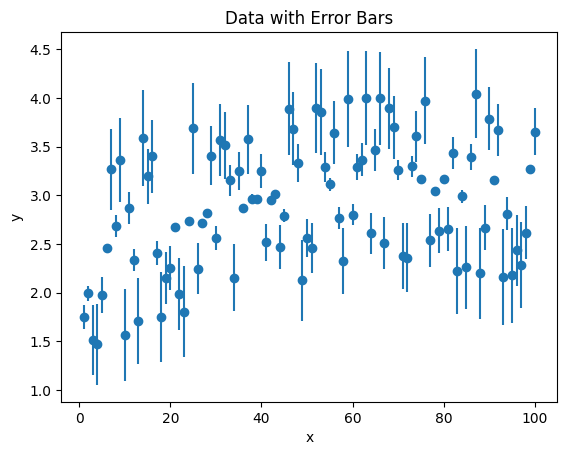

In [1]:
import numpy as np
import matplotlib.pyplot as plt


data = np.loadtxt('C:\\Users\\user\\OneDrive\\Desktop\\software\\data.txt')
x = data[:, 0]
y = data[:, 1]
sigma = data[:, 2]


plt.errorbar(x, y, yerr=sigma, fmt='o')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Data with Error Bars')
plt.show()


In [2]:
def y_theory(x, a, H):
    return a * (x ** H)

def log_likelihood(a, H, x, y, sigma):
    y_model = y_theory(x, a, H)
    return -0.5 * np.sum(((y - y_model) / sigma) ** 2)

def log_prior(a, H):
    if a <= 0 or H <= 0:
        return -np.inf
    return 0  # Uniform prior

def log_posterior(a, H, x, y, sigma):
    return log_likelihood(a, H, x, y, sigma) + log_prior(a, H)


In [3]:
def hamiltonian(momentum, potential):
    return 0.5 * np.sum(momentum ** 2) + potential

def gradient_log_posterior(a, H, x, y, sigma):
    epsilon = 1e-5
    grad_a = (log_posterior(a + epsilon, H, x, y, sigma) - log_posterior(a - epsilon, H, x, y, sigma)) / (2 * epsilon)
    grad_H = (log_posterior(a, H + epsilon, x, y, sigma) - log_posterior(a, H - epsilon, x, y, sigma)) / (2 * epsilon)
    return np.array([grad_a, grad_H])

def leapfrog(a, H, p, epsilon, x, y, sigma):
    p_half = p + 0.5 * epsilon * gradient_log_posterior(a, H, x, y, sigma)
    a_new = a + epsilon * p_half[0]
    H_new = H + epsilon * p_half[1]
    p_new = p_half + 0.5 * epsilon * gradient_log_posterior(a_new, H_new, x, y, sigma)
    return a_new, H_new, p_new

def microcanonical_hmc(x, y, sigma, n_samples=1000, epsilon=0.01, L=10):
    samples = []
    a_current = np.random.rand() * 2
    H_current = np.random.rand() * 2

    for _ in range(n_samples):
        p_current = np.random.randn(2)
        a_new, H_new = a_current, H_current
        p_new = p_current

        for _ in range(L):
            a_new, H_new, p_new = leapfrog(a_new, H_new, p_new, epsilon, x, y, sigma)

        p_new = -p_new  # Reverse momentum for symmetry
        current_H = hamiltonian(p_current, -log_posterior(a_current, H_current, x, y, sigma))
        new_H = hamiltonian(p_new, -log_posterior(a_new, H_new, x, y, sigma))

        if np.random.rand() < np.exp(current_H - new_H):
            a_current, H_current = a_new, H_new

        samples.append([a_current, H_current])

    return np.array(samples)


In [4]:
# Run Microcanonical HMC
samples_micro_hmc = microcanonical_hmc(x, y, sigma)

def standard_hmc(x, y, sigma, n_samples=1000, epsilon=0.01, L=10):
    samples = []
    a_current = np.random.rand() * 2
    H_current = np.random.rand() * 2

    for _ in range(n_samples):
        p_current = np.random.randn(2)
        a_new, H_new = a_current, H_current
        p_new = p_current

        for _ in range(L):
            a_new, H_new, p_new = leapfrog(a_new, H_new, p_new, epsilon, x, y, sigma)

        p_new = -p_new  # Reverse momentum for symmetry
        current_H = hamiltonian(p_current, -log_posterior(a_current, H_current, x, y, sigma))
        new_H = hamiltonian(p_new, -log_posterior(a_new, H_new, x, y, sigma))

        if np.random.rand() < np.exp(current_H - new_H):
            a_current, H_current = a_new, H_new

        samples.append([a_current, H_current])

    return np.array(samples)

samples_standard_hmc = standard_hmc(x, y, sigma)


mean_a_micro, mean_H_micro = np.mean(samples_micro_hmc, axis=0)
std_a_micro, std_H_micro = np.std(samples_micro_hmc, axis=0)

mean_a_standard, mean_H_standard = np.mean(samples_standard_hmc, axis=0)
std_a_standard, std_H_standard = np.std(samples_standard_hmc, axis=0)


print(f"Microcanonical HMC: a = {mean_a_micro:.4f} ± {std_a_micro:.4f}, H = {mean_H_micro:.4f} ± {std_H_micro:.4f}")
print(f"Standard HMC: a = {mean_a_standard:.4f} ± {std_a_standard:.4f}, H = {mean_H_standard:.4f} ± {std_H_standard:.4f}")


C:\Users\user\AppData\Local\Temp\ipykernel_21792\2072079402.py:6: RuntimeWarning: invalid value encountered in scalar subtract
  grad_a = (log_posterior(a + epsilon, H, x, y, sigma) - log_posterior(a - epsilon, H, x, y, sigma)) / (2 * epsilon)
C:\Users\user\AppData\Local\Temp\ipykernel_21792\2072079402.py:7: RuntimeWarning: invalid value encountered in scalar subtract
  grad_H = (log_posterior(a, H + epsilon, x, y, sigma) - log_posterior(a, H - epsilon, x, y, sigma)) / (2 * epsilon)


Microcanonical HMC: a = 0.7503 ± 0.0000, H = 0.4125 ± 0.0000
Standard HMC: a = 1.7891 ± 0.0000, H = 1.5267 ± 0.0000


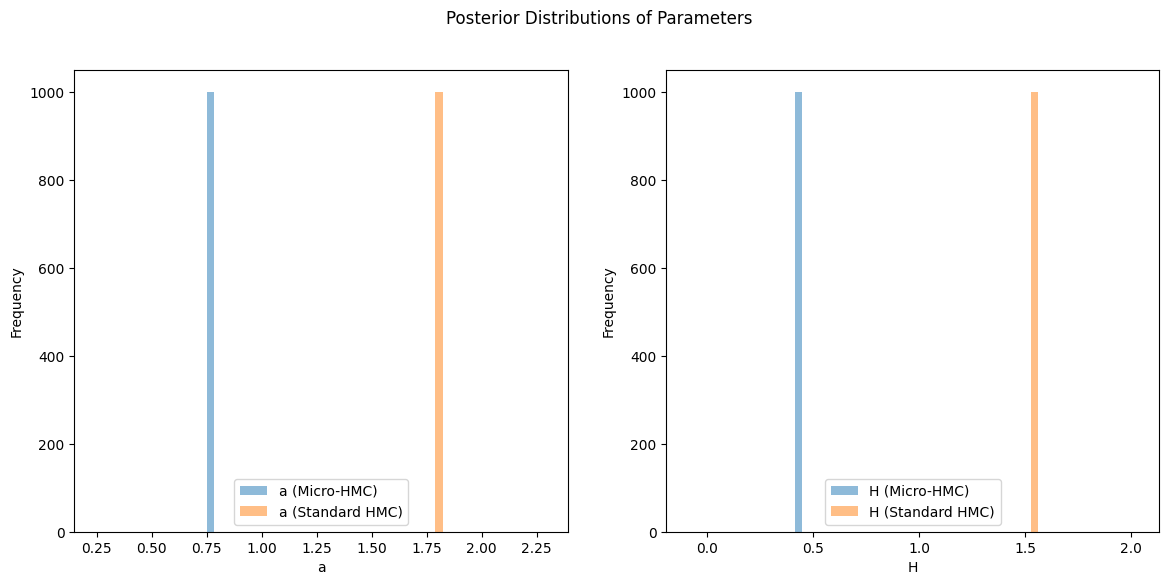

In [5]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.hist(samples_micro_hmc[:, 0], bins=30, alpha=0.5, label='a (Micro-HMC)')
plt.hist(samples_standard_hmc[:, 0], bins=30, alpha=0.5, label='a (Standard HMC)')
plt.xlabel('a')
plt.ylabel('Frequency')
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(samples_micro_hmc[:, 1], bins=30, alpha=0.5, label='H (Micro-HMC)')
plt.hist(samples_standard_hmc[:, 1], bins=30, alpha=0.5, label='H (Standard HMC)')
plt.xlabel('H')
plt.ylabel('Frequency')
plt.legend()

plt.suptitle('Posterior Distributions of Parameters')
plt.show()


Q2

In [7]:
import numpy as np

lambda_coef = 0.1
intensity = 0.1
num_iterations = 1000

In [8]:
data = np.loadtxt('C:\\Users\\user\\OneDrive\\Desktop\\software\\data.txt')


In [9]:
def potential_energy(theta, data):
   
    return np.sum((theta - data[:, 1]) ** 2) / 2

def kinetic_energy(p):
    return np.sum(p ** 2) / 2

def hamiltonian(theta, p, data):
    return potential_energy(theta, data) + kinetic_energy(p)

def gradient_potential_energy(theta, data):
   
    return theta - data[:, 1]

# Langevin force component
def langevin_force(intensity, size):
    return np.random.normal(0, intensity, size)

# Leapfrog integrator with friction and noise
def leapfrog(theta, p, data, lambda_coef, intensity, step_size, num_steps):
    for _ in range(num_steps):
        p -= 0.5 * step_size * (gradient_potential_energy(theta, data) + lambda_coef * p)
        theta += step_size * p
        p += 0.5 * step_size * (gradient_potential_energy(theta, data) + lambda_coef * p)
        p -= step_size * lambda_coef * p + langevin_force(intensity, theta.size)
    return theta, p

In [10]:
theta = np.zeros(data.shape[0])
p = np.random.normal(0, 1, data.shape[0])

#HMC
step_size = 0.1
num_steps = 10
for _ in range(num_iterations):
    p_current = np.random.normal(0, 1, data.shape[0])
    theta_proposed, p_proposed = leapfrog(theta, p_current, data, lambda_coef, intensity, step_size, num_steps)
    current_hamiltonian = hamiltonian(theta, p_current, data)
    proposed_hamiltonian = hamiltonian(theta_proposed, p_proposed, data)
    
    if np.random.uniform(0, 1) < np.exp(current_hamiltonian - proposed_hamiltonian):
        theta = theta_proposed


print(theta)

[-4.37380663 -0.90815967 -2.11928049 -1.78731523  7.09253384  4.76238449
  3.17770433 -0.09798731  3.37533116 -0.85944065 -2.03280036  3.43498537
  5.90828034  2.86244523  1.64028667  3.36372503 -0.37746011  7.71943801
  8.44108719  2.40790343 -0.7842284   3.94694735  2.57041055  5.28689262
  6.1752318   2.1782278   0.92545666  3.48423103  3.05272172 -1.65038991
  4.46049538  4.07381974  2.4255616   1.39347828  3.96227033  3.48862866
  3.12004808  3.5444803   2.32093599  0.93205885  0.35791847  3.03195263
  3.52767243  1.37424316  1.27728401  4.61427186 10.73350285  6.60815435
  5.96163653  4.07316427  2.84006331  5.23744947  1.58330959  2.43524964
 -1.33703927  5.71723373  1.86357252 -1.10932879  6.55157199  5.46623335
  1.35223783 -1.63323483  0.72975523 -1.35053356  5.63608565  1.71959717
  2.75472861  1.84176083  3.63036572  4.91573876  3.96705685  0.08001398
  1.81516332  4.25177474  2.18704828  3.21696859  2.56355203 11.51247844
 -1.60227258  2.10738349  8.69017627 -0.55244799  1

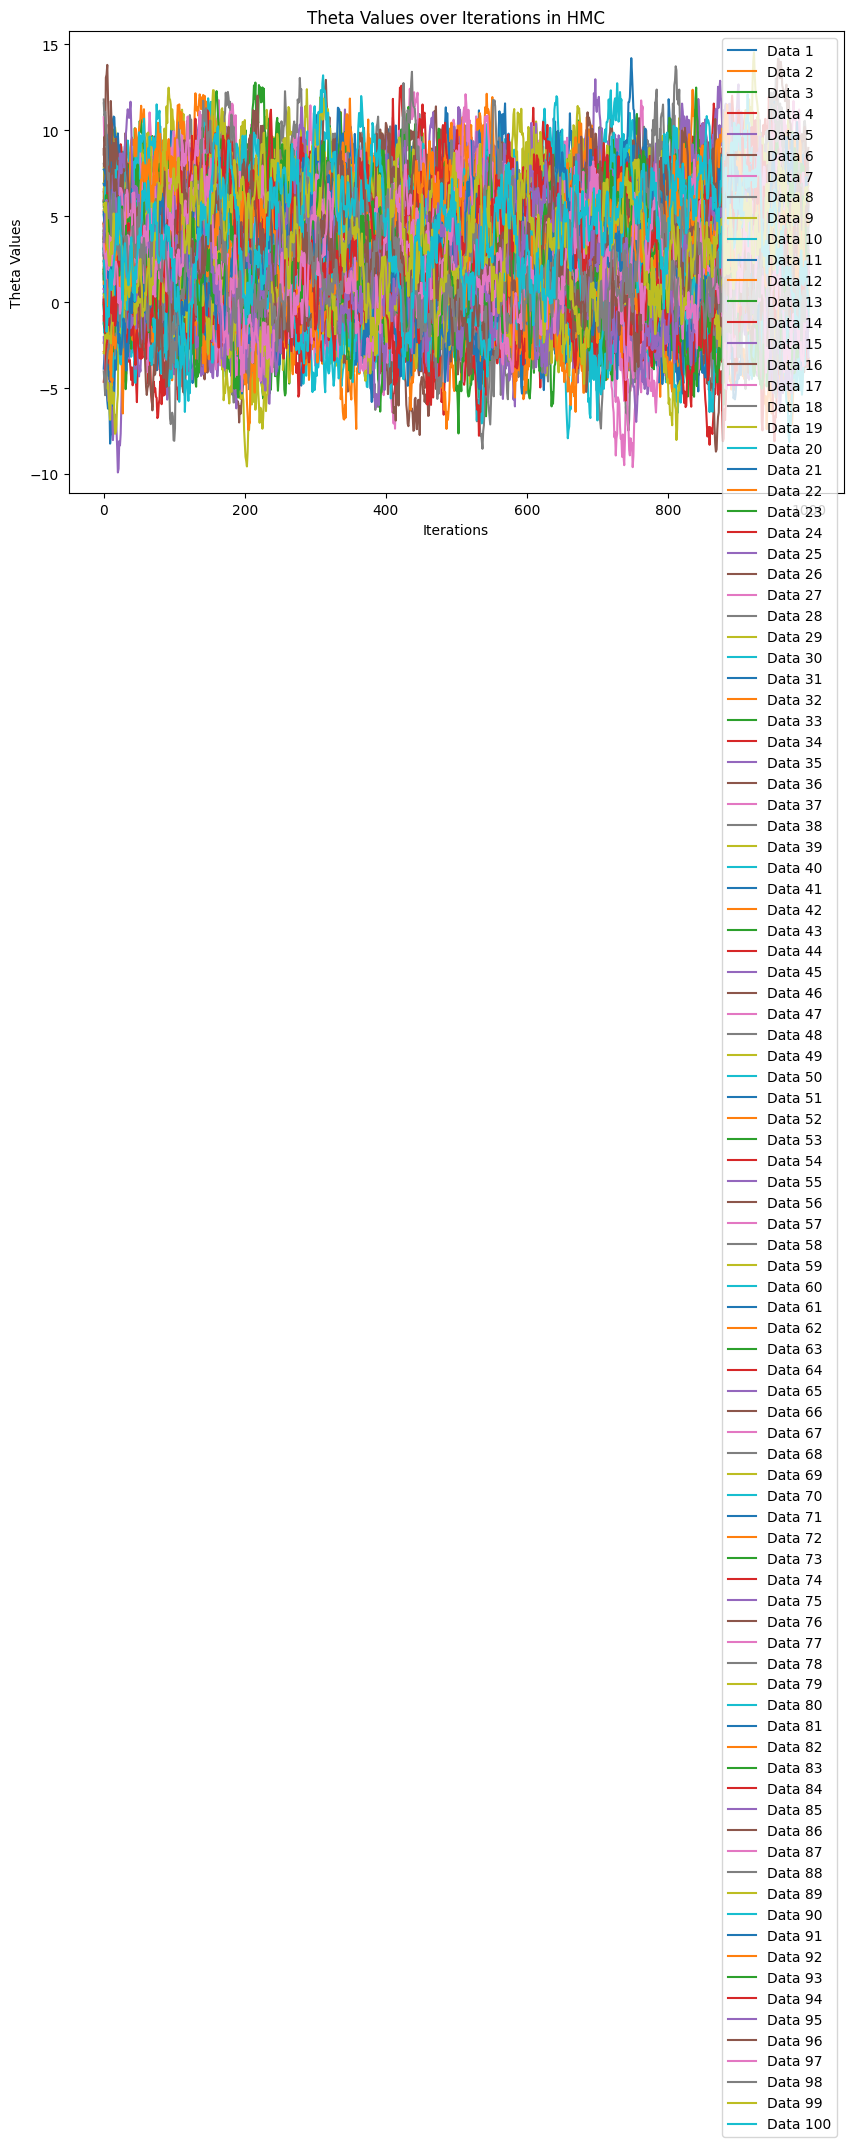

In [11]:
theta_values = []

# Run HMC
step_size = 0.1
num_steps = 10
for _ in range(num_iterations):
    p_current = np.random.normal(0, 1, data.shape[0])
    theta_proposed, p_proposed = leapfrog(theta, p_current, data, lambda_coef, intensity, step_size, num_steps)
    current_hamiltonian = hamiltonian(theta, p_current, data)
    proposed_hamiltonian = hamiltonian(theta_proposed, p_proposed, data)
    
    if np.random.uniform(0, 1) < np.exp(current_hamiltonian - proposed_hamiltonian):
        theta = theta_proposed
    
   
    theta_values.append(theta.copy())


theta_values = np.array(theta_values)


plt.figure(figsize=(10, 6))
for i in range(data.shape[0]):
    plt.plot(theta_values[:, i], label=f'Data {i+1}')
plt.xlabel('Iterations')
plt.ylabel('Theta Values')
plt.title('Theta Values over Iterations in HMC')
plt.legend()
plt.show()